# 01 Data audit

Counts per dataset, grade and split; duplicate handling; source image sizes; preprocessing example.

In [1]:
import json, os, sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option("display.max_columns", 40, "display.width", 200, "display.precision", 4)
RESULTS, CHECKPOINTS = ROOT / "results", ROOT / "checkpoints"

def require(*paths, hint):
    missing = [str(p) for p in paths if not Path(p).exists()]
    if missing:
        print("MISSING:", *missing, sep="\n  ")
        print("To create:", hint)
    return not missing

def runs():
    return sorted(p for p in CHECKPOINTS.iterdir() if (p / "run.json").is_file()) if CHECKPOINTS.is_dir() else []


In [2]:
MANIFEST = ROOT / "data" / "manifests" / "manifest.csv"
ok = require(MANIFEST, hint="python -m xaidr.cli prepare-data && python -m xaidr.cli make-splits")
if ok:
    from xaidr.data.manifest import read_manifest
    manifest = read_manifest(MANIFEST)
    display(manifest.groupby(["dataset", "split"]).size().rename("images").to_frame())
    used = manifest[manifest["split"].isin(["train", "val", "test"])]
    display(pd.crosstab(used["split"], used["grade"], margins=True))

images
dataset   split        
aptos2019           158
          test      526
          train    2452
          val       526

grade,0,1,2,3,4,All
split,,,,,,
test,270,51,138,27,40,526
train,1257,236,645,124,190,2452
val,269,51,139,26,41,526
All,1796,338,922,177,271,3504


In [3]:
DUPLICATES = ROOT / "data" / "splits" / "aptos2019_duplicates.csv"
if ok and require(DUPLICATES, hint="python -m xaidr.cli make-splits"):
    dup = pd.read_csv(DUPLICATES, keep_default_na=False)
    print("groups of byte-identical images:", dup["content_hash"].nunique(), "| images in them:", len(dup))
    display(dup["action"].value_counts().rename("images").to_frame())

groups of byte-identical images: 123 | images in them: 251


,images
action,
dropped_duplicate_copy,96
kept,93
dropped_conflicting_grades,62


In [4]:
if ok:
    sizes = manifest.assign(size=manifest["orig_w"].astype(str) + " x " + manifest["orig_h"].astype(str))
    display(sizes.groupby(["dataset", "size"]).size().sort_values(ascending=False).head(12).rename("images").to_frame())
    crop = manifest.assign(aspect=(manifest["crop_x1"] - manifest["crop_x0"]) / (manifest["crop_y1"] - manifest["crop_y0"]))
    print("crop width / height before padding:")
    display(crop.groupby("dataset")["aspect"].describe())

images
dataset   size               
aptos2019 1050 x 1050     974
          2416 x 1736     638
          2588 x 1958     533
          3216 x 2136     410
          2048 x 1536     351
          819 x 614       287
          3388 x 2588     141
          1504 x 1000      92
          1844 x 1226      61
          4288 x 2848      52
          640 x 480        42
          2896 x 1944      34

crop width / height before padding:


,count,mean,std,min,25%,50%,75%,max
dataset,,,,,,,,
aptos2019,3662.0,1.1802,0.1341,0.9946,1.0,1.2378,1.3001,1.3485


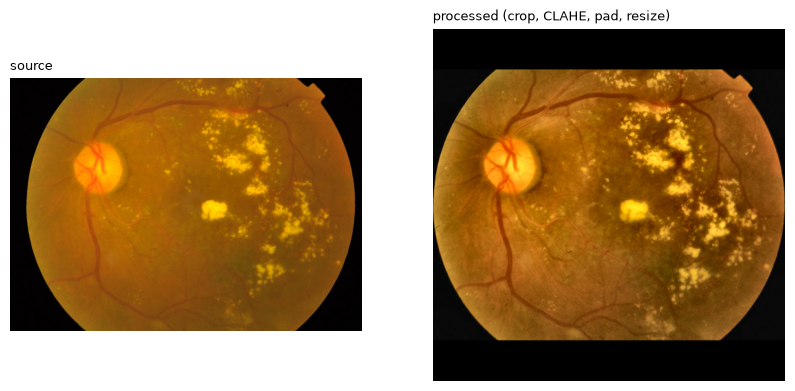

In [5]:
if ok:
    import matplotlib.pyplot as plt
    from xaidr.data.preprocess import read_image
    row = manifest[manifest["split"] == "test"].iloc[0]
    panels = [("processed (crop, CLAHE, pad, resize)", row["processed_path"])]
    if Path(row["source_path"]).is_file():
        panels.insert(0, ("source", row["source_path"]))
    fig, axes = plt.subplots(1, len(panels), figsize=(5 * len(panels), 5), squeeze=False)
    for ax, (title, path) in zip(axes[0], panels):
        ax.imshow(read_image(path)[..., ::-1]); ax.set_title(title, loc="left", fontsize=9); ax.set_axis_off()
    plt.show()

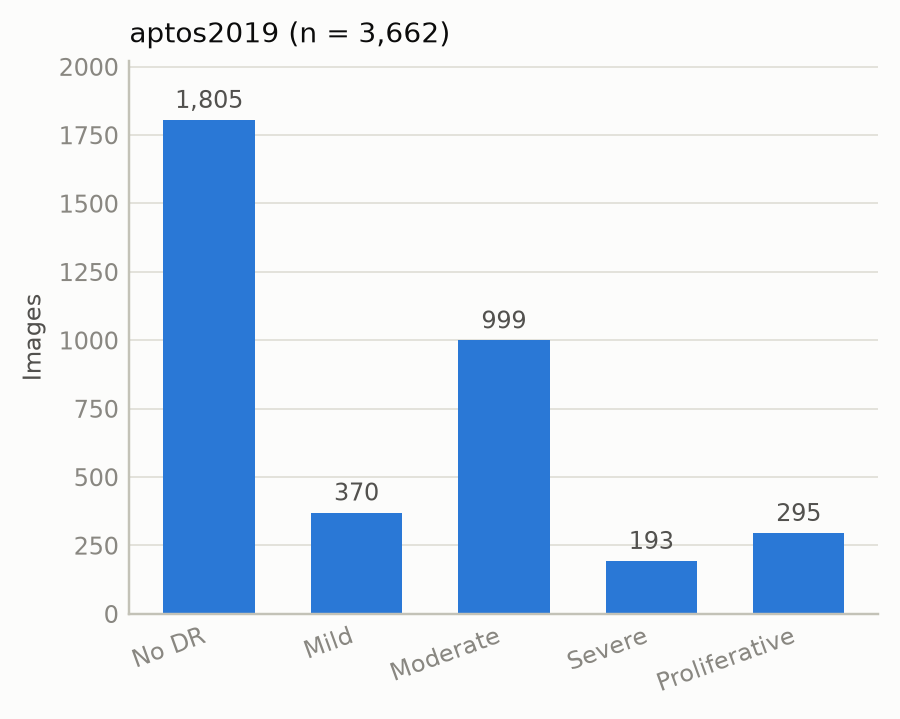

In [6]:
FIG = RESULTS / "figures" / "class_distribution.png"
if require(FIG, hint="python -m xaidr.cli figures --run <run id>"):
    display(Image(str(FIG), width=520))